# 04 — Uplift Modeling

Uplift modeling asks a different question from ordinary prediction: which treatment changes a customer's outcome relative to an alternative?

For each customer, potential outcomes are Y(No E-Mail), Y(Mens E-Mail), and Y(Womens E-Mail). Only one is observed. A T-Learner fits one outcome model per randomized arm and subtracts predicted probabilities to estimate uplift.

In [1]:
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "reports").exists(): ROOT = ROOT.parent
import pandas as pd
from IPython.display import display, Image
predictions = pd.read_csv(ROOT / "reports/uplift_predictions.csv")
policies = pd.read_csv(ROOT / "reports/uplift_policy_bootstrap_evaluation.csv")
print(f"Held-out customers: {len(predictions):,}")
display(predictions[["probability_no_email", "probability_mens_email", "probability_womens_email", "uplift_mens_email", "uplift_womens_email", "recommended_treatment"]].head())

Held-out customers: 12,800


,probability_no_email,probability_mens_email,probability_womens_email,uplift_mens_email,uplift_womens_email,recommended_treatment
0,0.147084,0.215183,0.149826,0.068099,0.002741,Mens E-Mail
1,0.083818,0.144643,0.109707,0.060825,0.025889,Mens E-Mail
2,0.035099,0.088688,0.106124,0.053590,0.071025,Womens E-Mail
3,0.033192,0.087585,0.105082,0.054394,0.071890,Womens E-Mail
4,0.127994,0.253437,0.193995,0.125443,0.066001,Mens E-Mail


## Counterfactual predictions and evaluation

Mens uplift is `P(visit | X, Mens E-Mail) - P(visit | X, No E-Mail)`. Womens uplift is defined analogously. These are modeled estimates, not directly observed individual causal effects.

For a policy d(X), inverse-propensity weighting estimates its visit rate using only rows where observed randomized assignment equals the policy recommendation:

$$\hat V(d)=\frac{1}{n}\sum_i \frac{I(A_i=d(X_i))Y_i}{e(A_i)}$$

The held-out evaluation uses e(A)=1/3 and 2,000 customer-level bootstrap resamples.

In [2]:
display(policies[["policy", "estimated_visit_rate", "incremental_vs_always_no_email", "incremental_ci_lower", "incremental_ci_upper", "difference_vs_always_mens_email", "difference_ci_lower_vs_always_mens_email", "difference_ci_upper_vs_always_mens_email"]])

,policy,estimated_visit_rate,incremental_vs_always_no_email,incremental_ci_lower,incremental_ci_upper,difference_vs_always_mens_email,difference_ci_lower_vs_always_mens_email,difference_ci_upper_vs_always_mens_email
0,always_no_email,0.105938,0.000000,0.000000,0.000000,-0.076641,-0.092578,-0.059760
1,always_mens_email,0.182578,0.076641,0.059760,0.092578,0.000000,0.000000,0.000000
2,always_womens_email,0.151875,0.045937,0.030703,0.060703,-0.030703,-0.048516,-0.014063
3,model_highest_positive_uplift,0.184922,0.078984,0.062338,0.094928,0.002344,-0.008437,0.012656
4,model_highest_predicted_visit,0.184922,0.078984,0.062338,0.094928,0.002344,-0.008437,0.012656


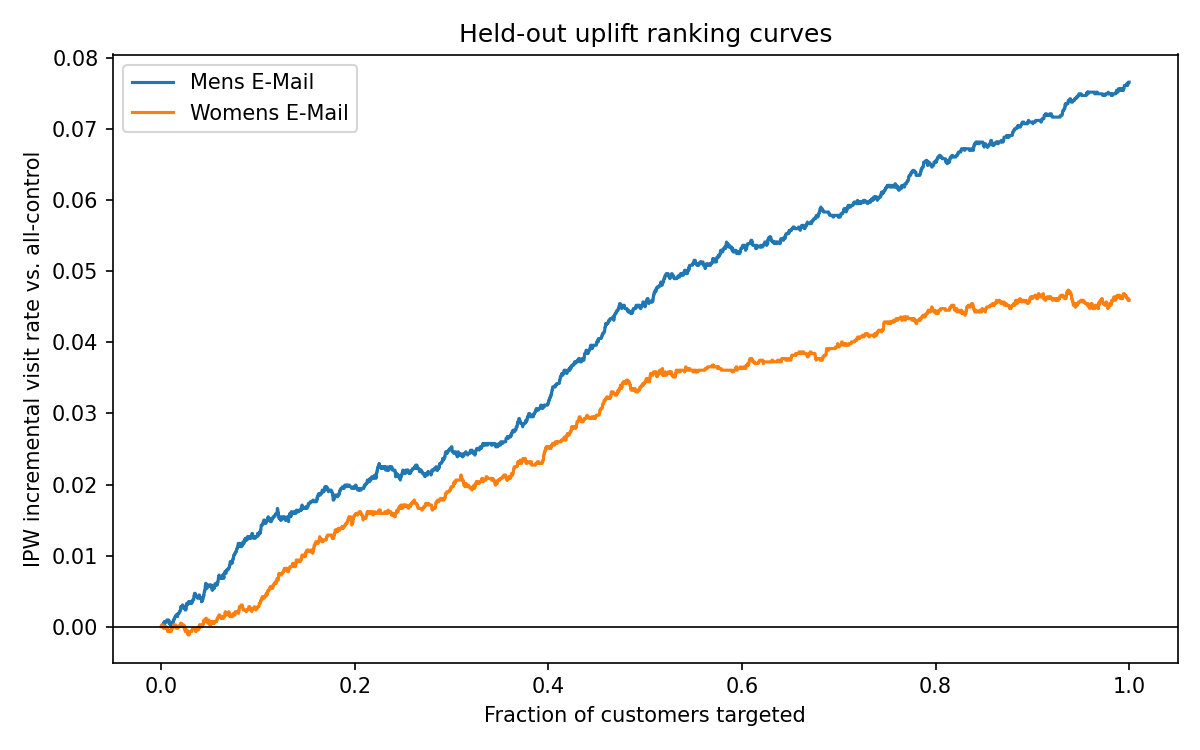

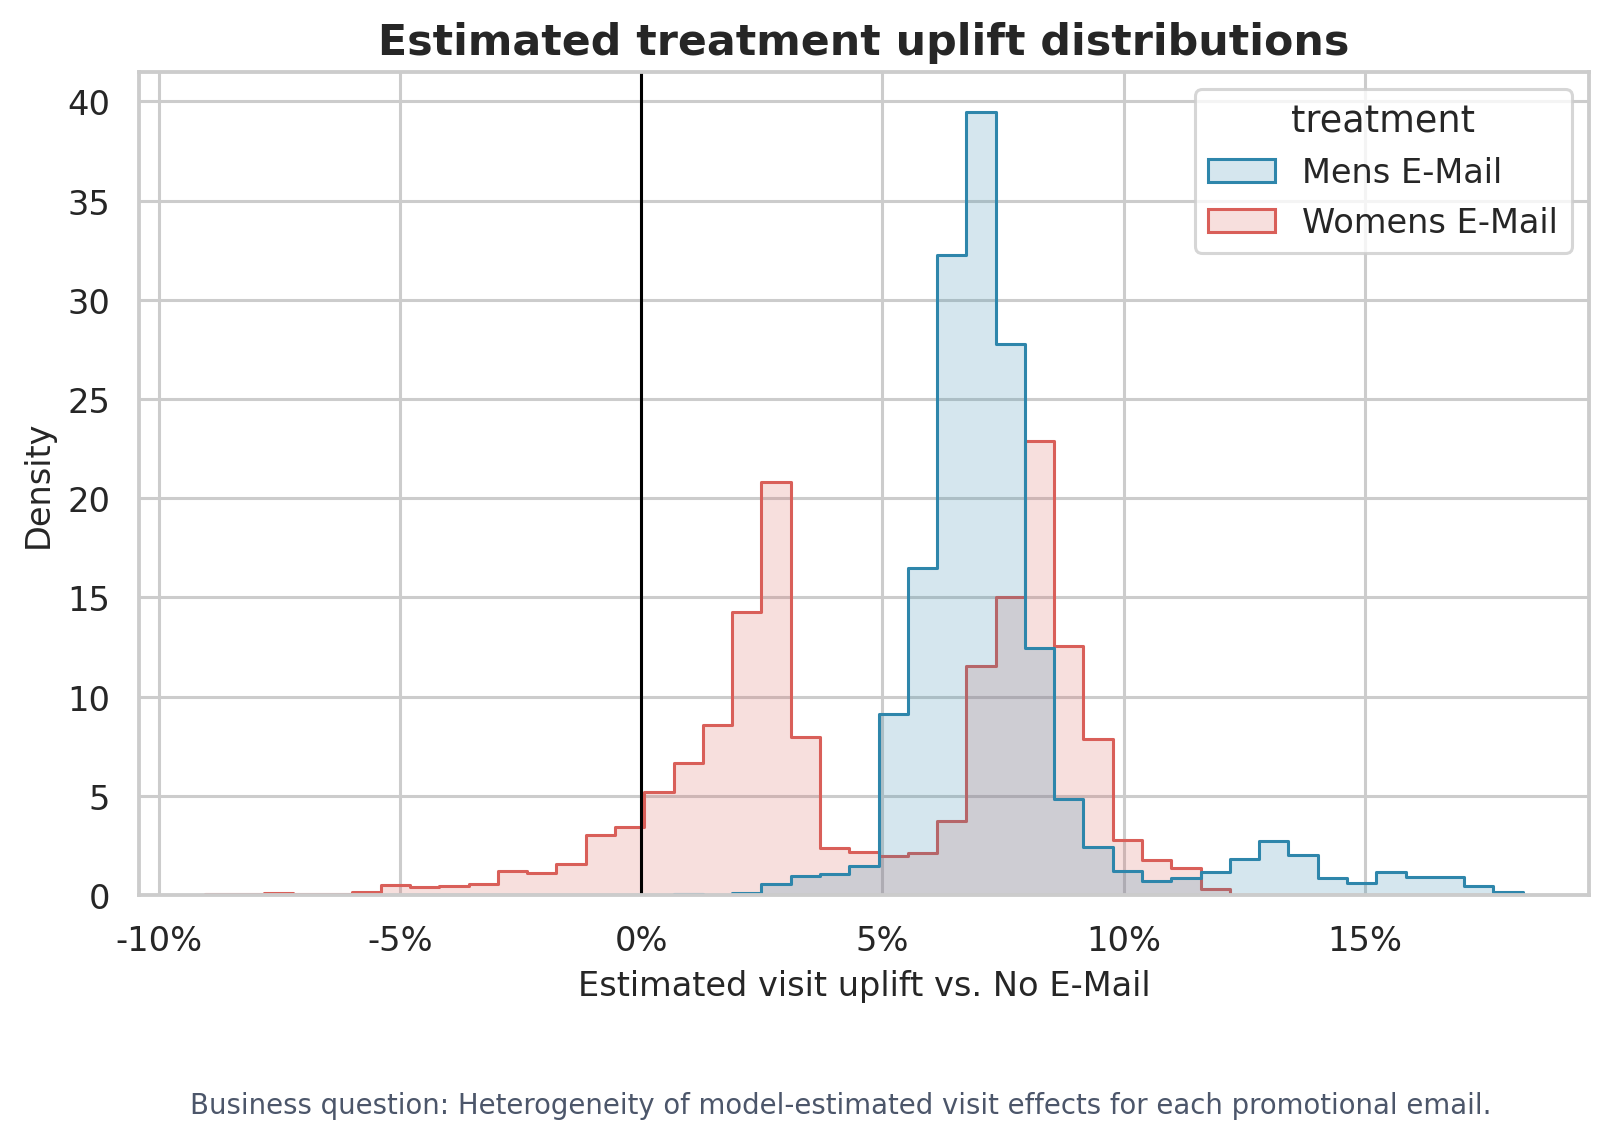

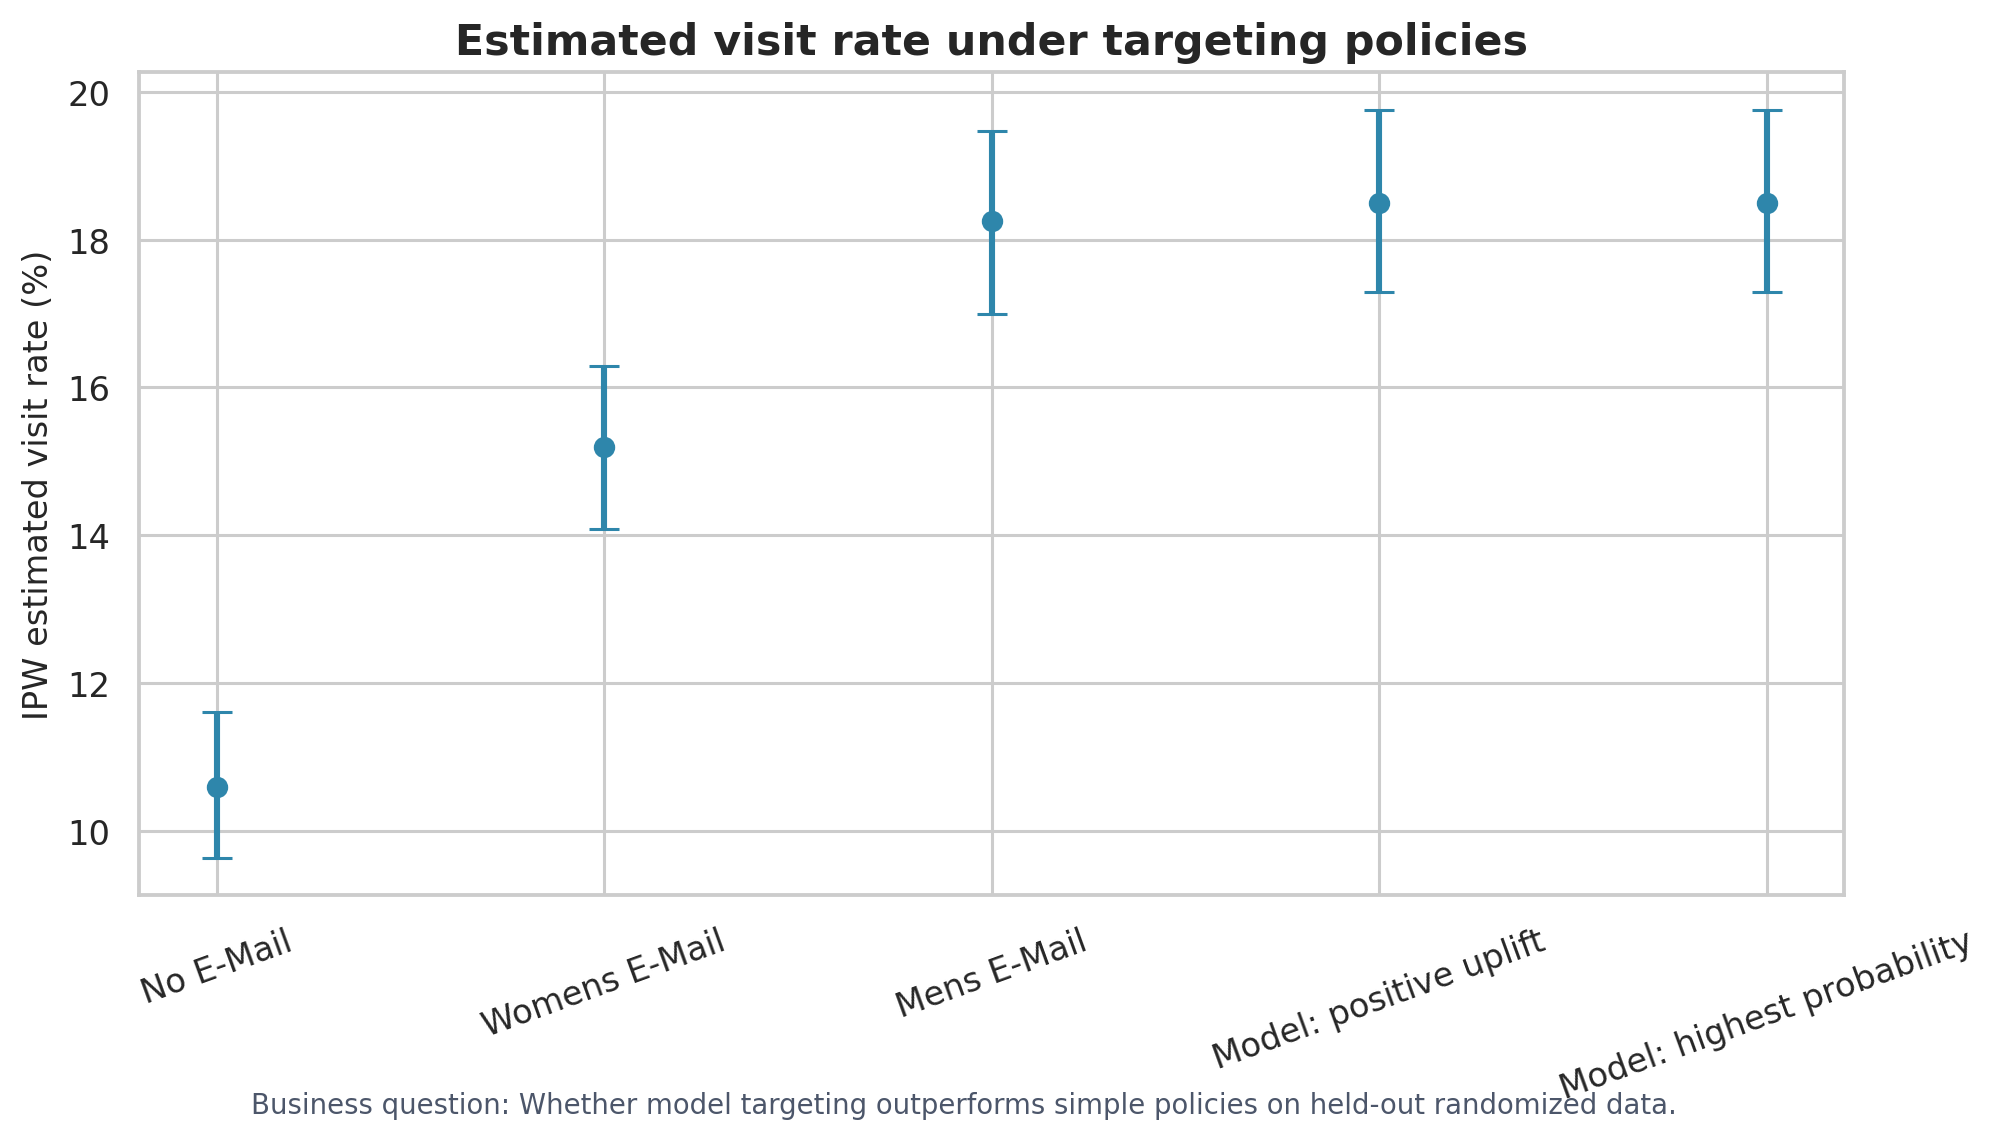

In [3]:
display(Image(filename=str(ROOT / "reports/figures/uplift_qini_curves.png")))
display(Image(filename=str(ROOT / "reports/figures/10_predicted_uplift_distributions.png")))
display(Image(filename=str(ROOT / "reports/figures/12_targeting_policy_performance.png")))

## Business interpretation

The positive-uplift policy estimates an 18.49% visit rate versus 10.59% for all-control and 18.26% for always-Mens. Its 0.23-point advantage over always-Mens has a bootstrap 95% interval from -0.84 to +1.27 points, so the model does not clearly outperform that simple policy. Do not compare raw outcomes among recommended and non-recommended customers: those groups are not randomized.

## Key Findings

- The T-Learner creates treatment-specific counterfactual predictions using pretreatment features.
- Model targeting is better than all-control and always-Womens in this held-out evaluation.
- Model targeting is not demonstrably better than always sending Mens E-Mail.
- A new randomized experiment is required before replacing the simple Mens benchmark.